# Trustfall Farms — Budget worker

This notebook is the **Budget** tile on the site. It answers five questions a small business owner (or a CFO) would ask:

1. **How much does it cost to start?**
2. **When does the cash come back?** (payback)
3. **Did we hit the budget, and if not, why?** (budget vs. actual)
4. **Which enterprises earn their keep?** (unit economics)
5. **Can the farm pay its owner a real wage?** (the Year 3 question)

**How to use it:** run the cells top to bottom (Runtime → Run all in Colab). Then go back to the assumptions file, change one number, and run it again to see what moves.

> Trustfall Farms is semi-fictional. Market anchors come from public sources; operating data is simulated and calibrated to them.

## 0. Setup
If you're in Google Colab, this downloads the project from GitHub. If you're running locally, it just finds the project folder.

In [1]:
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("trustfall-farms").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/charlesandrereynolds-dev/trustfall-farms.git"], check=True)
    os.chdir("trustfall-farms")

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "duckdb"], check=False)

import pandas as pd
import duckdb
import matplotlib.pyplot as plt
pd.set_option("display.float_format", "{:,.2f}".format)
print("Project folder:", ROOT)

Project folder: /home/claude/trustfall-farms


## 1. The assumptions log
Every number in this analysis traces back to one file: `data/assumptions.csv`. Each row has a value, a unit, and a **basis**:
- **Anchor**: backed by a public source
- **Est.**: an informed estimate
- **Owner plan / Owner choice**: a decision the owner made
- **Pending owner input**: placeholder awaiting a real number

*Why it matters:* when someone asks "where did that number come from?", you point here. Separating sourced numbers from estimates also tells you which inputs deserve a sensitivity test.

In [2]:
A = pd.read_csv(ROOT / "data/assumptions.csv", comment="#")
print(A["basis"].value_counts().to_string(), "\n")
A[["category", "key", "value", "unit", "basis"]]

basis
Est.                   43
Owner plan              7
Anchor                  4
Anchor + Est.           2
Owner choice            2
Pending owner input     2 



,category,key,value,unit,basis
0,eggs,hens_y1,15.00,hens,Owner plan
1,eggs,hens_y2,25.00,hens,Est.
2,eggs,hens_y3,30.00,hens,Est.
3,eggs,lay_rate_peak,0.75,eggs per hen per day,Est.
4,eggs,lay_rate_winter,0.35,eggs per hen per day,Est.
5,eggs,egg_price,7.00,$ per dozen,Anchor
6,eggs,egg_carton_cost,0.35,$ per dozen,Anchor
7,eggs,layer_feed_lb_per_hen_day,0.25,lb,Est.
8,eggs,layer_feed_price,0.52,$ per lb,Est.
9,rabbits,does,8.00,breeding does,Owner plan


## 2. Simulate three seasons of operations
`pipeline/simulate.py` turns the assumptions into weekly records for 2027–2029. It runs **twice**:
- **plan**: exactly what the assumptions say
- **actual**: the same farm with week-to-week randomness plus three realistic shocks (a late frost, wildfire smoke cancelling market days, a feed price spike)

A fixed random seed makes the "actuals" reproducible: anyone who reruns this gets the same numbers.

In [3]:
subprocess.run([sys.executable, str(ROOT / "pipeline/simulate.py")], check=True)
events = pd.read_csv(ROOT / "data/simulated/events.csv")
events

sales       1,464 rows
expenses    2,428 rows
labor       1,548 rows
financing       0 rows
events     3 rows


,date,event,description
0,2027-06-15,Late frost,Frost after transplanting cut year 1 produce b...
1,2028-08-08,Wildfire smoke,Two Oregon market days cancelled for smoke
2,2029-06-01,Feed price spike,Purchased feed up 12% from June


## 3. Load the data into a SQL database
DuckDB is a small analytical database that runs inside Python and queries CSV files directly. From here on, the analysis is mostly **SQL**, the same kind of queries you'd write against a company data warehouse.

In [4]:
con = duckdb.connect()
sim = ROOT / "data/simulated"
for t in ["sales", "expenses", "labor"]:
    con.execute(f"CREATE OR REPLACE VIEW {t} AS SELECT * FROM read_csv_auto('{sim / (t + '.csv')}')")
con.sql("SELECT * FROM sales LIMIT 5").df()

,scenario,week,season,channel,product,qty,unit,revenue
0,plan,2027-04-05,1,Farm direct,Eggs,4.55,dozen,31.85
1,plan,2027-04-12,1,Farm direct,Eggs,4.55,dozen,31.85
2,plan,2027-04-19,1,Farm direct,Eggs,4.55,dozen,31.85
3,plan,2027-04-26,1,Farm direct,Eggs,4.55,dozen,31.85
4,plan,2027-05-03,1,Farm direct,Eggs,5.06,dozen,35.44


## 4. Annual P&L: plan vs. actual
Revenue minus operating expenses equals operating profit. Startup capex is shown separately because it's a one-time investment, not a running cost.

In [5]:
pnl = con.sql('''
WITH rev AS (SELECT scenario, season, SUM(revenue) AS revenue FROM sales GROUP BY ALL),
     exp AS (SELECT scenario, season,
                    SUM(amount) FILTER (WHERE enterprise <> 'Capex') AS opex,
                    COALESCE(SUM(amount) FILTER (WHERE enterprise = 'Capex'), 0) AS capex
             FROM expenses GROUP BY ALL),
     hrs AS (SELECT scenario, season, SUM(hours) AS owner_hours FROM labor GROUP BY ALL)
SELECT scenario, season, revenue, opex, revenue - opex AS operating_profit, capex, owner_hours
FROM rev JOIN exp USING (scenario, season) JOIN hrs USING (scenario, season)
ORDER BY scenario DESC, season
''').df()
pnl

,scenario,season,revenue,opex,operating_profit,capex,owner_hours
0,plan,1,"10,189.16","6,523.55","3,665.61","23,000.00","1,114.38"
1,plan,2,"20,605.62","7,994.84","12,610.78",900.00,"1,284.29"
2,plan,3,"26,455.20","8,133.01","18,322.19",0.00,"1,327.39"
3,actual,1,"9,001.36","6,488.92","2,512.44","23,000.00","1,114.38"
4,actual,2,"18,564.32","7,774.05","10,790.27",900.00,"1,272.29"
5,actual,3,"25,980.78","8,247.29","17,733.49",0.00,"1,327.39"


## 5. Startup capex: what it costs to start
Shared assets (solar, truck) are counted only at the farm's **business-use share**. The rest belongs to the household, which is a separate analysis.

In [6]:
capex = con.sql('''
SELECT item, season AS year_spent, amount
FROM expenses WHERE scenario = 'actual' AND enterprise = 'Capex'
ORDER BY amount DESC
''').df()
print(f"Total startup capex: ${capex.amount.sum():,.0f}")
capex

Total startup capex: $23,900


,item,year_spent,amount
0,Solar array (farm share),1,"8,000.00"
1,Perimeter and garden fencing,1,"2,500.00"
2,Truck (farm share),1,"2,500.00"
3,Drip irrigation and hoses,1,"1,800.00"
4,Covered run (20x10 ft metal kit),1,"1,600.00"
5,Orchard trees and planting,1,"1,200.00"
6,Canopy tables scale and signage,1,"1,200.00"
7,Chest freezer and market coolers,1,"1,100.00"
8,Rabbit hutches (elevated along run walls),1,900.00
9,Hand tools (broadfork wheel hoe etc.),1,900.00


## 6. Payback: when does the cash come back?
Cumulative cash = every dollar in, minus every dollar out (capex included), month by month. The curve dips while you build, then climbs. Analysts call it a **J-curve**. **Payback** is the month it crosses zero.

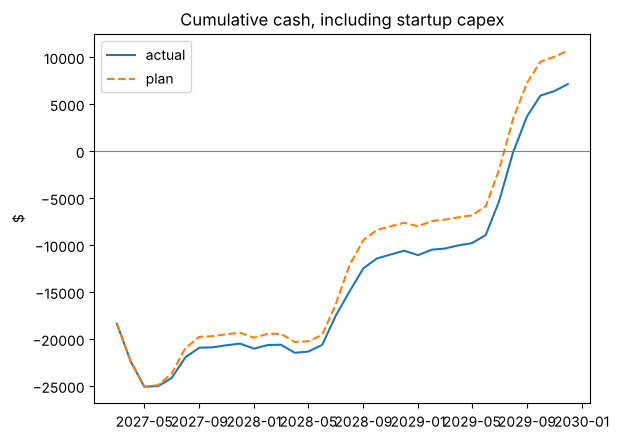

actual  payback: Sep 2029   lowest point: $-25,068
plan    payback: Aug 2029   lowest point: $-25,055


In [7]:
monthly = con.sql('''
WITH s AS (SELECT scenario, date_trunc('month', week) AS month, SUM(revenue) AS cash_in FROM sales GROUP BY ALL),
     e AS (SELECT scenario, date_trunc('month', date) AS month, SUM(amount) AS cash_out FROM expenses GROUP BY ALL)
SELECT scenario, month, COALESCE(cash_in, 0) - COALESCE(cash_out, 0) AS net
FROM s FULL JOIN e USING (scenario, month) ORDER BY scenario, month
''').df()
monthly["cumulative"] = monthly.groupby("scenario")["net"].cumsum()

for sc, g in monthly.groupby("scenario"):
    plt.plot(g["month"], g["cumulative"], label=sc, linestyle="--" if sc == "plan" else "-")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("Cumulative cash, including startup capex"); plt.ylabel("$"); plt.legend(); plt.show()

def payback(g):
    hit = g[g["cumulative"] >= 0]
    return hit["month"].iloc[0].strftime("%b %Y") if len(hit) else "Not within 3 seasons"
for sc, g in monthly.groupby("scenario"):
    print(f"{sc:7s} payback: {payback(g)}   lowest point: ${g['cumulative'].min():,.0f}")

## 7. Budget vs. actual: where did we miss, and why?
Variance = actual − plan. A negative variance on revenue is a miss. The point isn't the number; it's **the explanation**. Each big variance should tie to a cause (see the events table in step 2).

In [8]:
variance = con.sql('''
SELECT season, product,
       SUM(revenue) FILTER (WHERE scenario = 'plan')   AS plan,
       SUM(revenue) FILTER (WHERE scenario = 'actual') AS actual
FROM sales GROUP BY ALL ORDER BY season, plan DESC
''').df()
variance["variance"] = variance["actual"] - variance["plan"]
variance["variance_pct"] = variance["variance"] / variance["plan"] * 100
variance

,season,product,plan,actual,variance,variance_pct
0,1,Produce,"6,600.02","5,451.77","-1,148.25",-17.40
1,1,Rabbit,"1,942.50","2,005.59",63.09,3.25
2,1,Eggs,"1,206.09","1,157.50",-48.59,-4.03
3,1,Cottage foods,440.55,386.50,-54.05,-12.27
4,2,Produce,"10,149.98","8,422.79","-1,727.19",-17.02
5,2,Rabbit,"5,984.86","5,842.67",-142.19,-2.38
6,2,Eggs,"2,478.16","2,469.97",-8.19,-0.33
7,2,Honey,"1,213.29","1,143.46",-69.83,-5.76
8,2,Cottage foods,779.33,685.43,-93.90,-12.05
9,3,Produce,"11,600.02","11,018.70",-581.32,-5.01


In [9]:
by_market = con.sql('''
SELECT season, channel,
       SUM(revenue) FILTER (WHERE scenario = 'plan')   AS plan,
       SUM(revenue) FILTER (WHERE scenario = 'actual') AS actual
FROM sales GROUP BY ALL ORDER BY season, channel
''').df()
by_market["variance_pct"] = (by_market["actual"] / by_market["plan"] - 1) * 100
by_market

,season,channel,plan,actual,variance_pct
0,1,Farm direct,938.00,964.56,2.83
1,1,Rogue Valley Growers & Crafters (Saturday),"5,781.97","5,059.37",-12.50
2,1,Yreka Farmers Market,"3,469.19","2,977.43",-14.18
3,2,Farm direct,"4,239.78","4,364.99",2.95
4,2,Rogue Valley Growers & Crafters (Saturday),"10,228.66","8,425.65",-17.63
5,2,Yreka Farmers Market,"6,137.18","5,773.68",-5.92
6,3,Farm direct,"5,510.92","5,581.17",1.27
7,3,Rogue Valley Growers & Crafters (Saturday),"13,090.27","13,069.63",-0.16
8,3,Yreka Farmers Market,"7,854.01","7,329.98",-6.67


## 8. Unit economics: which enterprises earn their keep?
Some costs belong to one enterprise (layer feed → eggs). Others are **shared**: booth fees, mileage, insurance, utilities. A common, defensible method is to **allocate shared costs by revenue share**. Then divide each enterprise's margin by the owner hours it takes: **margin per hour** tells you where your time is best spent.

In [10]:
ent = con.sql('''
WITH rev AS (
  SELECT season, CASE product WHEN 'Rabbit' THEN 'Rabbits' WHEN 'Cottage foods' THEN 'Produce'
                              WHEN 'Orchard fruit' THEN 'Orchard' ELSE product END AS enterprise,
         SUM(revenue) AS revenue
  FROM sales WHERE scenario = 'actual' GROUP BY ALL),
direct AS (SELECT season, enterprise, SUM(amount) AS direct_cost FROM expenses
           WHERE scenario = 'actual' AND enterprise IN ('Eggs','Rabbits','Produce') GROUP BY ALL),
shared AS (SELECT season, SUM(amount) AS shared_cost FROM expenses
           WHERE scenario = 'actual' AND enterprise IN ('Markets','Fixed') GROUP BY ALL),
hrs AS (SELECT season, enterprise, SUM(hours) AS hours FROM labor WHERE scenario = 'actual' GROUP BY ALL),
mkt_hrs AS (SELECT season, hours AS market_hours FROM hrs WHERE enterprise = 'Markets')
SELECT r.season, r.enterprise, r.revenue,
       COALESCE(d.direct_cost, 0) AS direct_cost,
       s.shared_cost * r.revenue / SUM(r.revenue) OVER (PARTITION BY r.season) AS shared_cost,
       COALESCE(h.hours, 0) + m.market_hours * r.revenue / SUM(r.revenue) OVER (PARTITION BY r.season) AS owner_hours
FROM rev r
LEFT JOIN direct d USING (season, enterprise)
JOIN shared s USING (season)
LEFT JOIN hrs h USING (season, enterprise)
JOIN mkt_hrs m USING (season)
ORDER BY r.season, r.revenue DESC
''').df()
ent["margin"] = ent["revenue"] - ent["direct_cost"] - ent["shared_cost"]
ent["margin_per_hour"] = ent["margin"] / ent["owner_hours"]
ent[ent["season"] == 3]

,season,enterprise,revenue,direct_cost,shared_cost,owner_hours,margin,margin_per_hour
7,3,Produce,"12,033.32","1,490.55","1,963.81",542.27,"8,578.96",15.82
8,3,Rabbits,"7,930.55","1,301.45","1,294.25",444.59,"5,334.85",12.00
9,3,Eggs,"3,011.68","1,215.29",491.50,212.60,"1,304.89",6.14
10,3,Honey,"2,400.26",0.00,391.72,81.74,"2,008.54",24.57
11,3,Orchard,604.97,0.00,98.73,46.19,506.24,10.96


## 9. Can the farm pay its owner?
Two views of the same year:
- **Cash view:** operating profit, treating the owner's time as free (how most homesteads think)
- **Owner-wage view:** operating profit minus paying the owner the target wage for every hour worked

**Effective hourly wage** = operating profit ÷ owner hours. When it reaches the target, the farm is paying you a real wage. That's one of the Year 3 decision criteria.

In [11]:
target = float(A.set_index("key").loc["owner_wage_target", "value"])
wage = pnl[pnl["scenario"] == "actual"][["season", "operating_profit", "owner_hours"]].copy()
wage["effective_hourly"] = wage["operating_profit"] / wage["owner_hours"]
wage["profit_after_owner_wage"] = wage["operating_profit"] - wage["owner_hours"] * target
print(f"Target owner wage: ${target:.0f}/hr")
wage

Target owner wage: $20/hr


,season,operating_profit,owner_hours,effective_hourly,profit_after_owner_wage
3,1,"2,512.44","1,114.38",2.25,"-19,775.16"
4,2,"10,790.27","1,272.29",8.48,"-14,655.53"
5,3,"17,733.49","1,327.39",13.36,"-8,814.31"


## 10. The permaculture loop: feed garden savings
The feed garden (comfrey, sunflowers, amaranth, kale) replaces a growing share of purchased feed. Here's what that's worth each year, compared with buying all the feed.

In [12]:
offsets = A.set_index("key")["value"]
feed = con.sql('''
SELECT season, SUM(amount) AS purchased_feed FROM expenses
WHERE scenario = 'actual' AND item IN ('Layer feed', 'Rabbit feed', 'Doe upkeep') GROUP BY season ORDER BY season
''').df()
feed["offset"] = feed["season"].map(lambda y: float(offsets[f"feed_garden_offset_y{y}"]))
feed["feed_without_garden"] = feed["purchased_feed"] / (1 - feed["offset"])
feed["savings"] = feed["feed_without_garden"] - feed["purchased_feed"]
feed

,season,purchased_feed,offset,feed_without_garden,savings
0,1,"1,222.95",0.00,"1,222.95",0.00
1,2,"1,967.07",0.15,"2,314.20",347.13
2,3,"2,101.81",0.30,"3,002.59",900.78


## 11. Publish results to the website
This writes the key numbers to `docs/results.js`, which the site reads. After running, commit and push in GitHub Desktop, and the Budget tile updates.

In [13]:
import json
actual = monthly[monthly["scenario"] == "actual"]
results = {
  "budget": {
    "startup_capex": round(float(capex.amount.sum())),
    "capex_items": capex[["item", "amount"]].round(0).to_dict("records"),
    "payback": {sc: payback(g) for sc, g in monthly.groupby("scenario")},
    "lowest_cash": round(float(actual["cumulative"].min())),
    "pnl": pnl.round(0).to_dict("records"),
    "cumulative": {sc: [{"month": m.strftime("%Y-%m"), "cash": round(float(c))} for m, c in zip(g["month"], g["cumulative"])]
                   for sc, g in monthly.groupby("scenario")},
    "variance": variance.round(1).to_dict("records"),
    "enterprise_y3": ent[ent["season"] == 3].round(2).to_dict("records"),
    "wage": wage.round(2).to_dict("records"),
    "wage_target": target,
    "feed_savings": feed.round(0).to_dict("records"),
    "events": events.to_dict("records"),
  }
}
out = ROOT / "docs/results.js"
out.write_text("// Generated by notebooks/01_budget.ipynb. Do not edit by hand.\nwindow.TRUSTFALL_RESULTS = Object.assign(window.TRUSTFALL_RESULTS || {}, "
               + json.dumps(results, default=str, indent=1) + ");\n")
print("Wrote", out)

Wrote /home/claude/trustfall-farms/docs/results.js
